# Exploratory Data Analysis of Qwen2.5 Generated Labels

This notebook analyzes the soft labels (confidence scores) generated by Qwen2.5 for the RSNA MRI dataset.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)

## 1. Load Data
We will load the preprocessed data from `D:\Coding\kaggle\RSNA\data\main_data\train_folds_sota_qwen25.csv`.

In [16]:
DATA_PATH = r"D:\Coding\kaggle\RSNA\data\main_data\train_folds_sota_qwen25.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (4407, 15)


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,fold
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,0.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,0.0,0.0,0.3,0.0,0.8,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",0.0,1.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,0.0,0.3,0.0,0.0,0.8,0.2,0.9,0.0,0.0,0.0,0.0,0.0,4


## 2. Identify Target Columns
Let's identify the target columns we are predicting.

In [24]:
existing_targets = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ['study_id', 'fold', 'series_id', 'instance_number']]

print(f"Found {len(existing_targets)} target columns.")
print(existing_targets)

Found 12 target columns.
['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


## 3. Missing Values Check
Are there any missing values in the target confidence scores?

In [25]:
missing_vals = df[existing_targets].isnull().sum()
print("Missing values per target (Top 5):")
print(missing_vals[missing_vals > 0].head())
print(f"\nTotal columns with missing values: {(missing_vals > 0).sum()}")

Missing values per target (Top 5):
Series([], dtype: int64)

Total columns with missing values: 0


## 4. Class Prevalence (Distribution)
Let's see how prevalent each condition is, assuming a threshold of 0.5 means 'Positive'.

C:\Users\nishk\AppData\Local\Temp\ipykernel_54804\1481819523.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=prevalence.values[:20], y=prevalence.index[:20], palette="viridis")


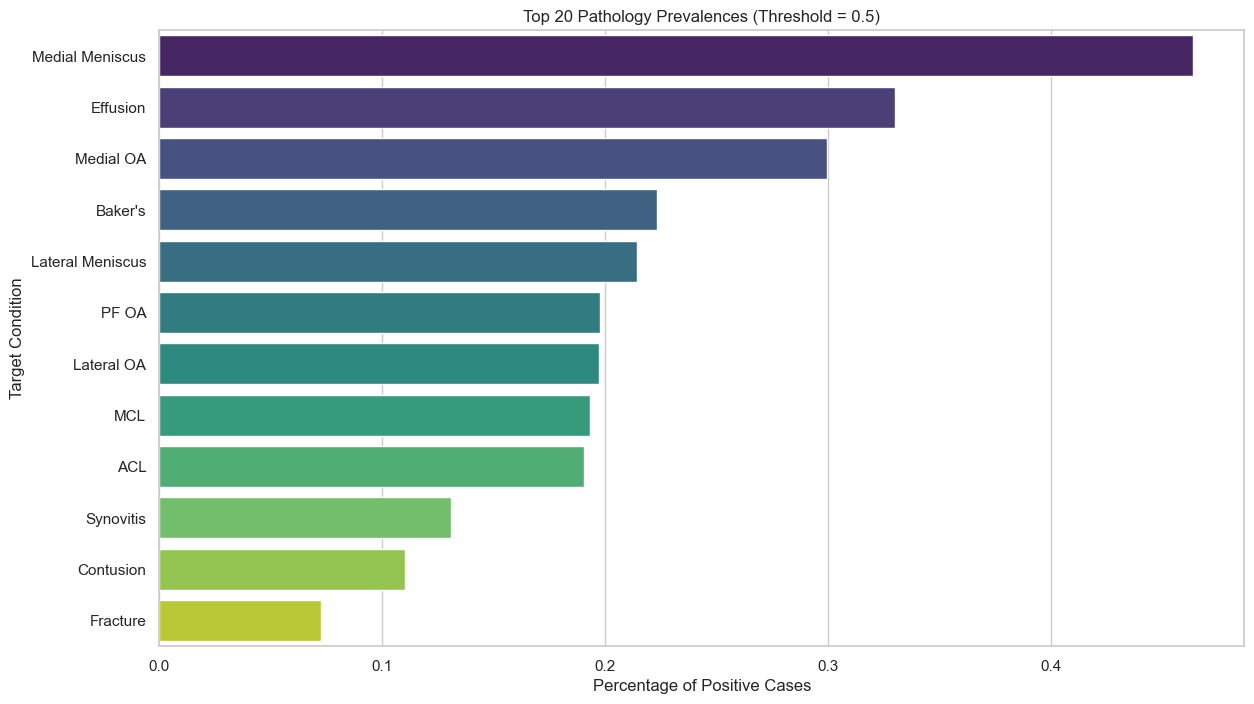

In [31]:
threshold = 0.5
prevalence = (df[existing_targets] >= threshold).mean().sort_values(ascending=False)

plt.figure(figsize=(14, 8))
sns.barplot(x=prevalence.values[:20], y=prevalence.index[:20], palette="viridis")
plt.title(f"Top 20 Pathology Prevalences (Threshold = {threshold})")
plt.xlabel("Percentage of Positive Cases")
plt.ylabel("Target Condition")
plt.show()

## 5. Confidence Score Distribution (Histograms)
Are the Qwen models confident (predicting near 0.0 and 1.0) or uncertain (predicting around 0.5)?

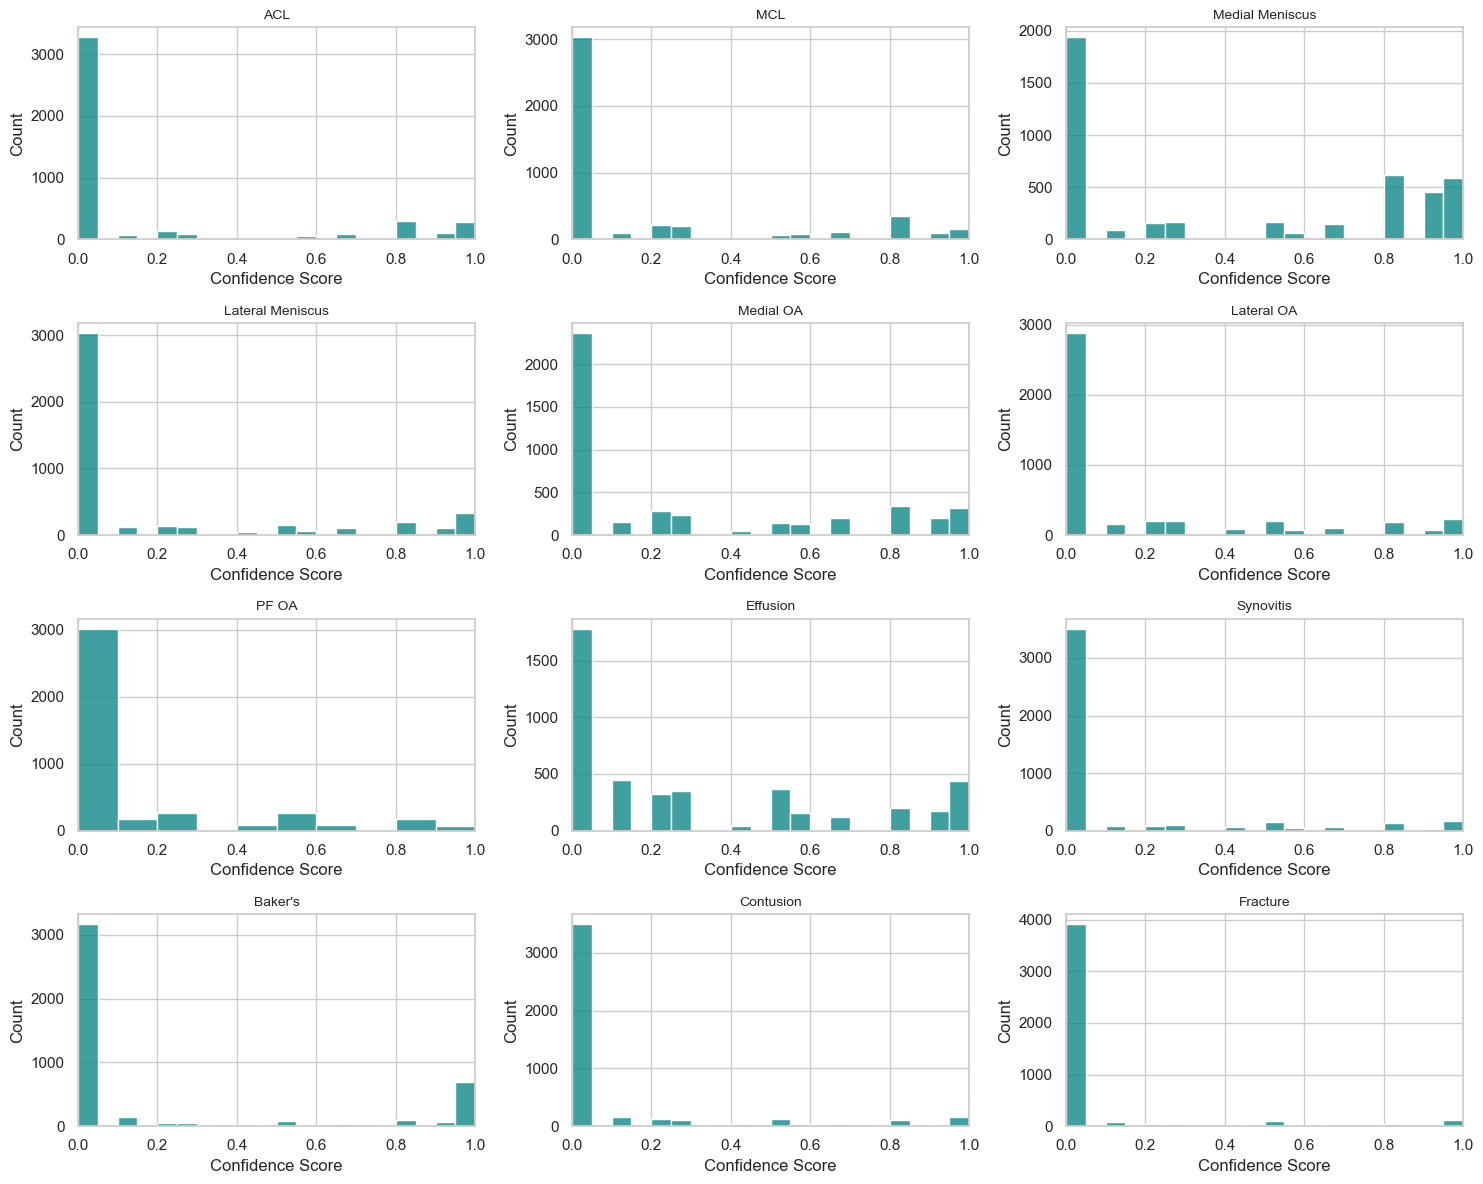

In [27]:
plt.figure(figsize=(15, 12))
for i, col in enumerate(existing_targets):  # Just plot the first 9 to keep it clean
    plt.subplot(4, 3, i + 1)
    sns.histplot(df[col].dropna(), bins=20, kde=False, color="teal")
    plt.title(col, fontsize=10)
    plt.xlim(0, 1)
    plt.xlabel("Confidence Score")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

## 6. Correlation Heatmap
Do some pathologies co-occur frequently?

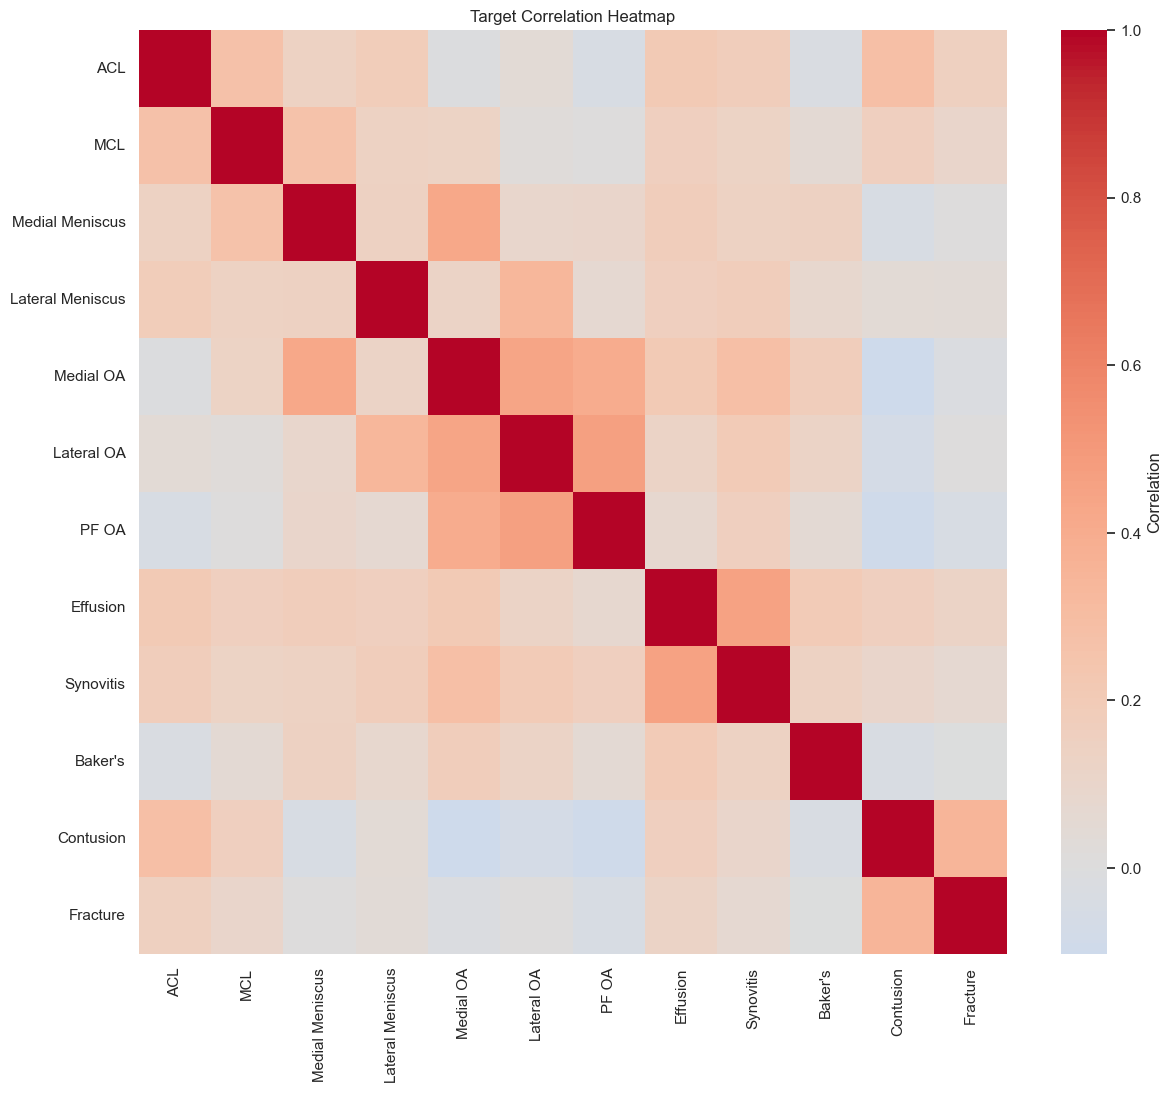

In [28]:
plt.figure(figsize=(14, 12))
corr_matrix = df[existing_targets].corr()

sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, cbar_kws={'label': 'Correlation'})
plt.title("Target Correlation Heatmap")
plt.show()

## 7. Fold Balance Analysis
Finally, let's verify if our K-Folds are well-stratified across the positive cases.

Samples per fold:
fold
0    882
1    882
2    881
3    881
4    881
Name: count, dtype: int64


C:\Users\nishk\AppData\Local\Temp\ipykernel_54804\3912641751.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='fold', y=top_target, palette="Set2")


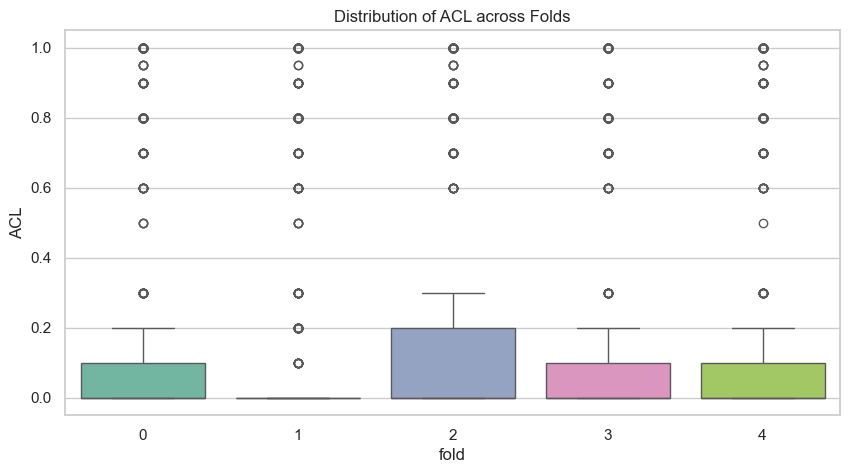

In [29]:
if 'fold' in df.columns:
    fold_counts = df['fold'].value_counts().sort_index()
    print("Samples per fold:")
    print(fold_counts)
    
    # Check mean confidence score per fold for a top target to ensure stratification
    top_target = existing_targets[0]
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x='fold', y=top_target, palette="Set2")
    plt.title(f"Distribution of {top_target} across Folds")
    plt.show()
else:
    print("No 'fold' column found in the dataset.")

In [3]:
import numpy as np
data = np.load(r"D:\Coding\kaggle\RSNA\data\1.2.826.0.1.3680043.8.498.10000477131564453926848372798213249270.npz")
print(data.files)
print(data[data.files[0]].shape)
print (data['data'][:5])


['data']
(24, 224, 224)
[[[ 0  1  1 ...  1  1  1]
  [ 1  8  8 ...  7  6  5]
  [ 0  4  6 ...  5  4  4]
  ...
  [ 1  9  7 ...  3  4  2]
  [ 1  8  5 ...  5  4  4]
  [ 1  4  3 ...  4  3  2]]

 [[ 0  1  1 ...  1  1  1]
  [ 1  8  7 ...  7  6  6]
  [ 1 10 10 ...  8  7  6]
  ...
  [ 1  4  3 ...  3  4  3]
  [ 0  3  3 ...  5  5  5]
  [ 1  8  6 ...  5  3  3]]

 [[ 0  1  1 ...  0  1  1]
  [ 1  5  8 ...  4  8  7]
  [ 1  6  8 ...  4  3  7]
  ...
  [ 1  7  5 ...  3  2  4]
  [ 1  4  4 ...  5  7  7]
  [ 1  7  6 ...  2  3  4]]

 [[ 0  0  0 ...  1  2  1]
  [ 0  3  4 ...  7 13 10]
  [ 0  5  8 ...  7 10  8]
  ...
  [ 1  7  7 ...  7  9  4]
  [ 1  7  9 ... 10  7  3]
  [ 0  4  5 ...  6  6  6]]

 [[ 0  1  1 ...  0  0  1]
  [ 1  7  9 ...  3  2  6]
  [ 1  6  7 ...  8  3  6]
  ...
  [ 1  5  4 ...  3  5  3]
  [ 1  7  6 ...  7  6  6]
  [ 0  4  4 ...  8  4  8]]]


In [ ]:
import os
import pandas as pd
import numpy as np

CSV_PATH = r"D:\Coding\kaggle\RSNA\data\main_data\train (1).csv"

EXPECTED_12_CLASSES = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

def verify_12_classes_positive_instances(csv_path: str = CSV_PATH):
    print("=" * 100)
    print(" RSNA 12-CLASS VERIFICATION: POSITIVE INSTANCE CHECK (MINIMUM 1 POSITIVE SAMPLE)")
    print("=" * 100)

    if not os.path.exists(csv_path):
        print(f"[ERROR] File not found: {csv_path}")
        return

    df = pd.read_csv(csv_path)
    total_rows = len(df)
    print(f"Loaded {total_rows:,} rows from: {csv_path}\n")

    results = []
    all_passed = True

    for cls_name in EXPECTED_12_CLASSES:
        # 1. Column presence check
        if cls_name not in df.columns:
            results.append({
                "Class": cls_name,
                "Column Exists": "❌ No",
                "Non-Null Count": 0,
                "Positive (1s)": 0,
                "Negative (0s)": 0,
                "Status": "❌ MISSING COLUMN"
            })
            all_passed = False
            continue

        series = pd.to_numeric(df[cls_name], errors="coerce")
        non_null_cnt = series.notnull().sum()

        if non_null_cnt == 0:
            results.append({
                "Class": cls_name,
                "Column Exists": "✅ Yes",
                "Non-Null Count": 0,
                "Positive (1s)": 0,
                "Negative (0s)": 0,
                "Status": "⚠️ ALL NaN (No Annotations)"
            })
            all_passed = False
            continue

        # Count positive (>= 0.5 or == 1) and negative (< 0.5 or == 0)
        pos_count = (series >= 0.5).sum()
        neg_count = (series < 0.5).sum()

        # Check if at least 1 positive sample exists
        if pos_count >= 1:
            status = f"✅ PASS ({pos_count} positive{'s' if pos_count > 1 else ''})"
        else:
            status = "❌ FAIL (0 positives found!)"
            all_passed = False

        results.append({
            "Class": cls_name,
            "Column Exists": "✅ Yes",
            "Non-Null Count": f"{non_null_cnt:,}",
            "Positive (1s)": f"{pos_count:,}",
            "Negative (0s)": f"{neg_count:,}",
            "Status": status
        })

    # Display clean table
    results_df = pd.DataFrame(results)
    print(results_df.to_string(index=False))

    # Overall Summary
    print("\n" + "=" * 100)
    if all_passed:
        print("🎯 RESULT: ALL 12 classes exist and have at least 1 positive instance (value = 1) in the dataset!")
    else:
        print("⚠️ RESULT: One or more classes are missing, completely null, or have 0 positive instances.")
    print("=" * 100)

if __name__ == "__main__":
    verify_12_classes_positive_instances()


 RSNA 12-CLASS VERIFICATION: POSITIVE INSTANCE CHECK (MINIMUM 1 POSITIVE SAMPLE)
Loaded 4,407 rows from: D:\Coding\kaggle\RSNA\data\main_data\train (1).csv

           Class Column Exists Non-Null Count Positive (1s) Negative (0s)                Status
             ACL         ✅ Yes             58            24            34 ✅ PASS (24 positives)
             MCL         ✅ Yes             58             9            49  ✅ PASS (9 positives)
 Medial Meniscus         ✅ Yes             58            26            32 ✅ PASS (26 positives)
Lateral Meniscus         ✅ Yes             58            23            35 ✅ PASS (23 positives)
       Medial OA         ✅ Yes             58            15            43 ✅ PASS (15 positives)
      Lateral OA         ✅ Yes             58            11            47 ✅ PASS (11 positives)
           PF OA         ✅ Yes             58            21            37 ✅ PASS (21 positives)
        Effusion         ✅ Yes             58            35            23 ✅

: 